# 03 · Global DeepAR model (LSTM + Negative Binomial likelihood)
Rubric items: *Architecture Logic*, *Theoretical Rigor*, *DL Dataset & Regularization*

**Idea (Salinas et al., 2020).** Instead of one model per SKU, train **one recurrent network on all 300 SKUs**.
The network learns patterns shared across products (weekly cycle, SNAP and event effects, price response),
and an **item embedding** lets it keep what is specific to each SKU. It outputs a full **probability distribution**,
so we get quantiles (prediction intervals), not only a point forecast.

In [1]:
%run ./00_common.ipynb
P = load_panel()
SEEDS = [0, 1, 2]

common loaded | ROOT=/Users/Harsh/Downloads/inventory-demand-forecasting 2 | device=cpu | H=28, C=56, origins={'O1': 915, 'O2': 943, 'O3': 971}


## 1. Theory
### 1.1 Probabilistic, autoregressive factorisation
For SKU $i$ with history up to origin $t_0$ and known covariates $\mathbf x$:
$$p(y_{t_0+1:t_0+H}\mid y_{1:t_0},\mathbf x)=\prod_{t=t_0+1}^{t_0+H} p\big(y_t\mid \theta(\mathbf h_t)\big),\qquad
\mathbf h_t=\mathrm{LSTM}\big(\mathbf h_{t-1},\,[y_{t-1}/\nu,\ \mathbf x_t,\ \mathbf e_{item},\ \mathbf e_{dept}]\big)$$

### 1.2 LSTM cell (why not a plain RNN)
$$\begin{aligned}
f_t&=\sigma(W_f[h_{t-1},u_t]+b_f) & i_t&=\sigma(W_i[h_{t-1},u_t]+b_i) & o_t&=\sigma(W_o[h_{t-1},u_t]+b_o)\\
\tilde c_t&=\tanh(W_c[h_{t-1},u_t]+b_c) & c_t&=f_t\odot c_{t-1}+i_t\odot\tilde c_t & h_t&=o_t\odot\tanh(c_t)
\end{aligned}$$
In a vanilla RNN, $\partial h_t/\partial h_{t-k}$ is a product of $k$ Jacobians → it vanishes or explodes.
In the LSTM the cell state is updated **additively**, so $\partial c_t/\partial c_{t-1}=f_t$; with forget gates near 1
the gradient flows across many weeks (long-term dependencies such as the weekly cycle over an 84-day window).
We still clip the gradient norm at 10 to guard against explosions (Pascanu et al., 2013).

### 1.3 Why a Negative Binomial likelihood
Sales are **non-negative integers**, often 0, and **over-dispersed** (variance > mean). A Gaussian puts mass on negative
values and has constant shape. The NB has mean $\mu$ and variance $\mu+\alpha\mu^2$ — the extra $\alpha$ captures
over-dispersion; as $\alpha\to0$ it becomes Poisson.

### 1.4 Scale handling
Items differ in volume by 100×. Inputs are divided by $\nu=1+\text{mean(context)}$ and the outputs are re-scaled:
$\mu=\nu\cdot\mathrm{softplus}(\cdot)$, $\alpha=\mathrm{softplus}(\cdot)/\sqrt\nu$. One set of weights then fits all SKUs.

### 1.5 Training and forecasting
* **Training (teacher forcing):** feed the *true* $y_{t-1}$, maximise $\sum_t m_t\log p(y_t\mid\theta_t)$ where the mask
  $m_t=0$ on stockout / not-on-sale days (the "mark, don't impute" rule turns into "don't learn from censored zeros").
* **Forecasting (ancestral sampling):** after encoding the 56-day context, draw $\tilde y_{t_0+1}\sim p(\cdot\mid\theta)$, feed it back
  as the next input, repeat for 28 steps; 200 sample paths → empirical quantiles q10/q50/q90 and the mean.

### 1.6 Regularisation used
| technique | where | why |
|---|---|---|
| Dropout 0.1 | between LSTM layers and before the output head | reduces co-adaptation (Srivastava et al., 2014) |
| Weight decay 1e-4 (AdamW) | all weights | L2 penalty ≈ Gaussian prior on weights (MAP) |
| **Item-ID dropout** 0.1 | item embedding replaced by an "unknown item" vector | forces the net to also work from shared features; enables cold-start |
| Early stopping (patience 5) | validation NLL on the 28 days before the origin | stops before over-fitting |
| LR decay (ReduceLROnPlateau ×0.5) | optimiser | finer steps near a minimum |
| Gradient clipping (norm 10) | optimiser | exploding gradients in RNNs |
| Random window sampling | data | every epoch sees new (SKU, start-day) windows → data augmentation |

## 2. Check the likelihood implementation (technical validation)
Our hand-written NB log-probability must equal PyTorch's reference implementation, and samples must have
mean μ and variance μ + αμ².

In [2]:
mu = torch.tensor([0.3, 2.0, 15.0]); alpha = torch.tensor([0.5, 0.2, 0.05]); y = torch.tensor([0.0, 3.0, 12.0])
ref = torch.distributions.NegativeBinomial(total_count=1 / alpha, probs=alpha * mu / (1 + alpha * mu)).log_prob(y)
print("ours:", nb_log_prob(y, mu, alpha).numpy().round(5), "\ntorch:", ref.numpy().round(5))
assert torch.allclose(nb_log_prob(y, mu, alpha), ref, atol=1e-5)
smp = torch.distributions.NegativeBinomial(total_count=1 / alpha, probs=alpha * mu / (1 + alpha * mu)).sample((200000,))
print("sample mean:", smp.mean(0).numpy().round(3), " target:", mu.numpy())
print("sample var :", smp.var(0).numpy().round(3), " target:", (mu + alpha * mu ** 2).numpy().round(3))

ours: [-0.27952 -1.8853  -2.59476] 
torch: [-0.27952 -1.8853  -2.59476]
sample mean: [ 0.3    2.002 14.997]  target: [ 0.3  2.  15. ]
sample var : [ 0.346  2.802 26.209]  target: [ 0.345  2.8   26.25 ]


## 3. Model size

In [3]:
n_dyn = make_batch(P, [0], [ORIGINS["O1"]], MODEL_CFG)["dyn"].shape[-1]
m_tmp = DeepAR(P["N"], 3, n_dyn, MODEL_CFG)
print(m_tmp)
print("input features per step:", n_dyn, "+ embeddings =", n_dyn + MODEL_CFG["emb_item"] + MODEL_CFG["emb_dept"])
print("trainable parameters:", sum(p.numel() for p in m_tmp.parameters()))

DeepAR(
  (item_emb): Embedding(301, 10)
  (dept_emb): Embedding(3, 2)
  (rnn): LSTM(29, 40, num_layers=2, batch_first=True, dropout=0.1)
  (drop): Dropout(p=0.1, inplace=False)
  (head): Linear(in_features=40, out_features=2, bias=True)
)
input features per step: 17 + embeddings = 29
trainable parameters: 27578


## 4. Train for the first origin and inspect the learning curve

In [4]:
t0 = time.time()
model_o1, hist_o1 = train_deepar(P, ORIGINS["O1"], seed=0)
print(f"training time {time.time()-t0:.0f}s, best epoch {hist_o1.val_nll.idxmin()+1}")

epoch  1  train NLL 1.5298  val NLL 1.4841  lr 2.0e-03


epoch  2  train NLL 1.4721  val NLL 1.4254  lr 2.0e-03


epoch  3  train NLL 1.4507  val NLL 1.4088  lr 2.0e-03


epoch  4  train NLL 1.4369  val NLL 1.3971  lr 2.0e-03


epoch  5  train NLL 1.4306  val NLL 1.3887  lr 2.0e-03


epoch  6  train NLL 1.4334  val NLL 1.3842  lr 2.0e-03


... (22 outputs left out)

epoch 29  train NLL 1.3986  val NLL 1.3683  lr 5.0e-04


epoch 30  train NLL 1.3917  val NLL 1.3682  lr 2.5e-04


epoch 31  train NLL 1.4029  val NLL 1.3677  lr 2.5e-04


epoch 32  train NLL 1.3969  val NLL 1.3675  lr 2.5e-04
training time 45s, best epoch 27


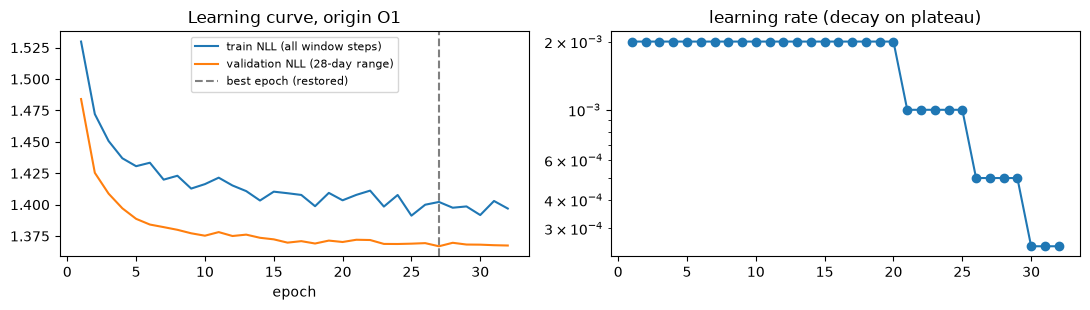

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(hist_o1.epoch, hist_o1.train_nll, label="train NLL (all window steps)")
ax[0].plot(hist_o1.epoch, hist_o1.val_nll, label="validation NLL (28-day range)")
ax[0].axvline(hist_o1.val_nll.idxmin() + 1, ls="--", c="grey", label="best epoch (restored)")
ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=8); ax[0].set_title("Learning curve, origin O1")
ax[1].plot(hist_o1.epoch, hist_o1.lr, marker="o"); ax[1].set_yscale("log"); ax[1].set_title("learning rate (decay on plateau)")
plt.tight_layout(); plt.savefig(FIG / "03_learning_curve.png", dpi=150); plt.show()

## 5. Rolling-origin backtest: 3 origins × 3 seeds
A new model is trained for every origin (only data before the origin is used). Three random seeds show how much the
result depends on initialisation — a single run of a neural network is not enough evidence.

In [6]:
MODEL_DIR = ROOT / "results" / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
frames, hists = [], []
for name, o in ORIGINS.items():
    for seed in SEEDS:
        if name == "O1" and seed == 0:
            model, hist = model_o1, hist_o1
        else:
            model, hist = train_deepar(P, o, seed=seed, verbose=False)
        torch.save(model.state_dict(), MODEL_DIR / f"deepar_{name}_s{seed}.pt")
        smp = forecast_deepar(model, P, o, seed=seed)
        frames.append(samples_to_frame(smp, P, name, o, "deepar", extra={"seed": seed}))
        hists.append(hist.assign(origin=name, seed=seed))
        print(f"{name} seed {seed}: epochs {len(hist)}, best val NLL {hist.val_nll.min():.4f}")
deepar = pd.concat(frames, ignore_index=True)
deepar.to_parquet(FC / "deepar.parquet")
pd.concat(hists).to_csv(TAB / "03_training_histories.csv", index=False)

O1 seed 0: epochs 32, best val NLL 1.3669


O1 seed 1: epochs 40, best val NLL 1.3634


O1 seed 2: epochs 37, best val NLL 1.3671


O2 seed 0: epochs 34, best val NLL 1.3786


O2 seed 1: epochs 36, best val NLL 1.3765


O2 seed 2: epochs 30, best val NLL 1.3757


O3 seed 0: epochs 29, best val NLL 1.4385


O3 seed 1: epochs 33, best val NLL 1.4371


O3 seed 2: epochs 15, best val NLL 1.4410


In [7]:
ev = attach_actuals(deepar, P)
per_run = ev.groupby(["seed"]).apply(score)
print("DeepAR, mean ± std over seeds (all origins pooled):")
pd.DataFrame({"mean": per_run.mean(), "std": per_run.std()}).T.round(4)

DeepAR, mean ± std over seeds (all origins pooled):


,MAE,RMSE,WAPE,Pinball,Cov80,Width80,n
mean,1.3352,2.5820,0.6406,0.3943,0.9127,3.6699,25200.0
std,0.0082,0.0162,0.0040,0.0026,0.0023,0.0060,0.0


In [8]:
base = pd.concat([pd.read_parquet(FC / f"{m}.parquet") for m in ("seasonal_naive", "lightgbm", "kalman")])
quick = pd.concat([attach_actuals(base, P), ev[ev.seed == 0]]).groupby("model").apply(score)
quick[["MAE", "RMSE", "WAPE", "Pinball", "Cov80"]].round(4).sort_values("Pinball")

,MAE,RMSE,WAPE,Pinball,Cov80
model,,,,,
deepar,1.3429,2.5956,0.6444,0.3960,0.9102
lightgbm,1.3615,2.6647,0.6533,0.4026,0.8015
kalman,1.3246,2.5711,0.6356,0.4158,0.8698
seasonal_naive,1.5774,3.3424,0.7569,0.5137,0.8430


## 6. Forecast examples (fan charts)

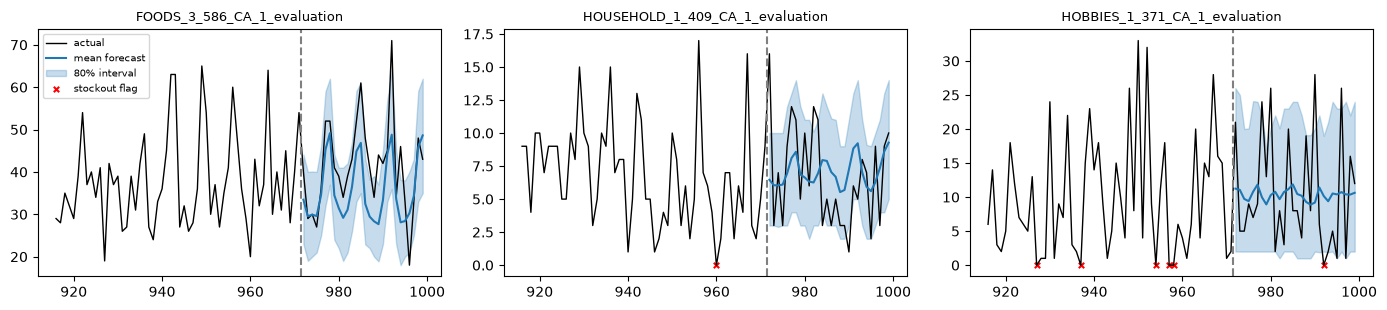

In [9]:
model_o3 = DeepAR(P["N"], 3, n_dyn, MODEL_CFG); model_o3.load_state_dict(torch.load(MODEL_DIR / "deepar_O3_s0.pt")); model_o3.eval()
fc_o3 = deepar[(deepar.origin == "O3") & (deepar.seed == 0)]
meta = P["meta"]
examples = [int(meta.index[(meta.dept_id == d)][meta.loc[meta.dept_id == d, "mean_sales"].argmax()]) for d in CFG["depts"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, i in zip(axes, examples):
    plot_fan(ax, P, i, ORIGINS["O3"], fc_o3, title=meta.id[i])
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "03_fan_charts.png", dpi=150); plt.show()

## 7. What did the item embeddings learn? 
Each SKU has a 10-dimensional learned vector. Projecting with PCA (via SVD) shows whether the network discovered
structure it was never told about explicitly (e.g. sales volume or department).

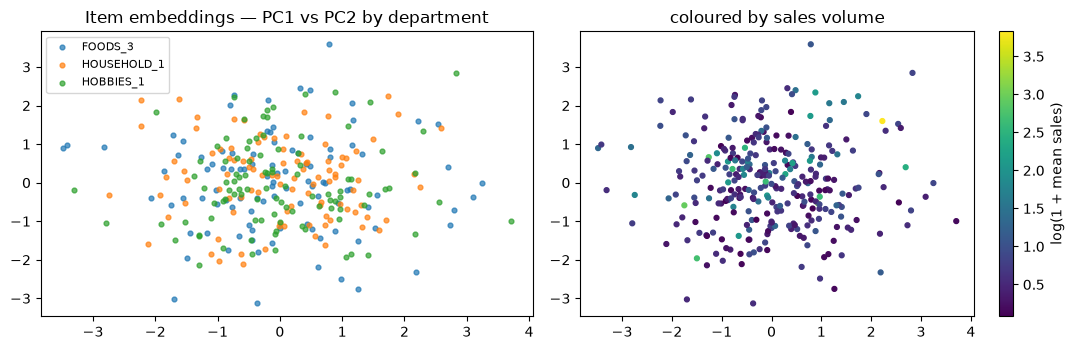

explained variance of first 2 PCs: [0.135 0.123]
corr(PC1, log mean sales): -0.013


In [10]:
E = model_o3.item_emb.weight.detach().numpy()[:P["N"]]
Ec = E - E.mean(0)
U, Sv, Vt = np.linalg.svd(Ec, full_matrices=False)
pcs = Ec @ Vt[:2].T
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for d in CFG["depts"]:
    k = meta.dept_id == d
    ax[0].scatter(pcs[k, 0], pcs[k, 1], s=12, label=d, alpha=0.7)
ax[0].legend(fontsize=8); ax[0].set_title("Item embeddings — PC1 vs PC2 by department")
sc = ax[1].scatter(pcs[:, 0], pcs[:, 1], c=np.log1p(meta.mean_sales), s=12, cmap="viridis")
plt.colorbar(sc, ax=ax[1], label="log(1 + mean sales)"); ax[1].set_title("coloured by sales volume")
plt.tight_layout(); plt.savefig(FIG / "03_embedding_pca.png", dpi=150); plt.show()
print("explained variance of first 2 PCs:", (Sv[:2] ** 2 / (Sv ** 2).sum()).round(3))
print("corr(PC1, log mean sales):", np.corrcoef(pcs[:, 0], np.log1p(meta.mean_sales))[0, 1].round(3))

**Interpretation.** The embeddings are *not* organised by sales volume: the volume is already removed by the scale ν,
so the embedding only needs to store what is left — the *shape* of demand (weekday pattern, burstiness), which is
spread over many directions (the first two PCs explain only ~25% of the variance). This is a useful check that scaling works
as intended.

## 8. Take-aways
* One network with ~28k parameters forecasts all 300 SKUs and produces full predictive distributions.
* Early stopping on a validation window placed *before* each origin, plus dropout, weight decay and item-ID dropout,
  keep the gap between train and validation NLL small.
* The comparison with the baselines (and the hybrid) is done properly in notebook 06; ablations of each design
  choice are in notebook 05.